In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

### Get data

**Measurements**

In [2]:
g = 9.81 

l = 1.105   # IF IN LAST PLOT MY LINE IS TOO LAW, MAKE l smaller, so line gows up
sigma_l = 0.0005 

d = 1.15  
sigma_d = 0.0005

w = 0.019
sigma_w = 0.0005

**Data from computer**

In [3]:
df = pd.read_csv('/home/gea/Desktop/Lab 1/quad_pendolo_2_2025.txt', header=None, delim_whitespace=True,
                   names=["t", "T", "tT"])


In [4]:
df.head()

,t,T,tT
0,2.632223,2.139798,0.011594
1,3.702083,2.139614,0.011634
2,4.771837,2.139390,0.011674
3,5.841473,2.139210,0.011710
4,6.911047,2.139039,0.011746


### Speed

#### Measure speed

In [5]:
import tensorflow as tf

def compute_v0(w, l, d, transit):
    return (w / transit) * (l / d)

def compute_v0_and_uncertainty(w, l, d, transit, sigma_w, sigma_l, sigma_d):

    w = tf.constant(w, dtype=tf.float32)
    l = tf.constant(l, dtype=tf.float32)
    d = tf.constant(d, dtype=tf.float32)
    transit = tf.constant(transit, dtype=tf.float32)

    with tf.GradientTape(persistent=True) as tape:
        tape.watch([w, l, d])
        v0 = compute_v0(w, l, d, transit)

    dv0_dw = tape.gradient(v0, w)
    dv0_dl = tape.gradient(v0, l)
    dv0_dd = tape.gradient(v0, d)

    sigma_v0_squared = (dv0_dw * sigma_w)**2 + (dv0_dl * sigma_l)**2 + (dv0_dd * sigma_d)**2
    sigma_v0 = tf.sqrt(sigma_v0_squared)

    return v0.numpy(), sigma_v0.numpy()

2025-04-27 15:17:23.515975: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-04-27 15:17:23.534001: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-04-27 15:17:23.710521: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-04-27 15:17:23.907853: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-04-27 15:17:24.080020: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been 

In [6]:
v0_results = [compute_v0_and_uncertainty(
    w=w, l=l, d=d, transit=transit_val,
    sigma_w=sigma_w, sigma_l=sigma_l, sigma_d=sigma_d
) for transit_val in df["tT"]]


df['v0'], sigma_v0 = zip(*v0_results)

# sigma_v0 = np.full(len(df.t), min(sigma_v0))

In [7]:
df.head()

,t,T,tT,v0
0,2.632223,2.139798,0.011594,1.574653
1,3.702083,2.139614,0.011634,1.569239
2,4.771837,2.139390,0.011674,1.563862
3,5.841473,2.139210,0.011710,1.559054
4,6.911047,2.139039,0.011746,1.554276


#### Plot speed

In [8]:
def exp_decay(t, v0_0, lambda_):
    return v0_0 * np.exp(-lambda_ * t)

popt, pcov = curve_fit(exp_decay, df.t, df.v0, sigma=sigma_v0, p0=(df['v0'].iloc[0], 0.1))
v0_0_fit, lambda_fit = popt
tau = 1 / lambda_fit

In [26]:
tau

384.7677697806397

/tmp/ipykernel_13423/4115637579.py:18: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


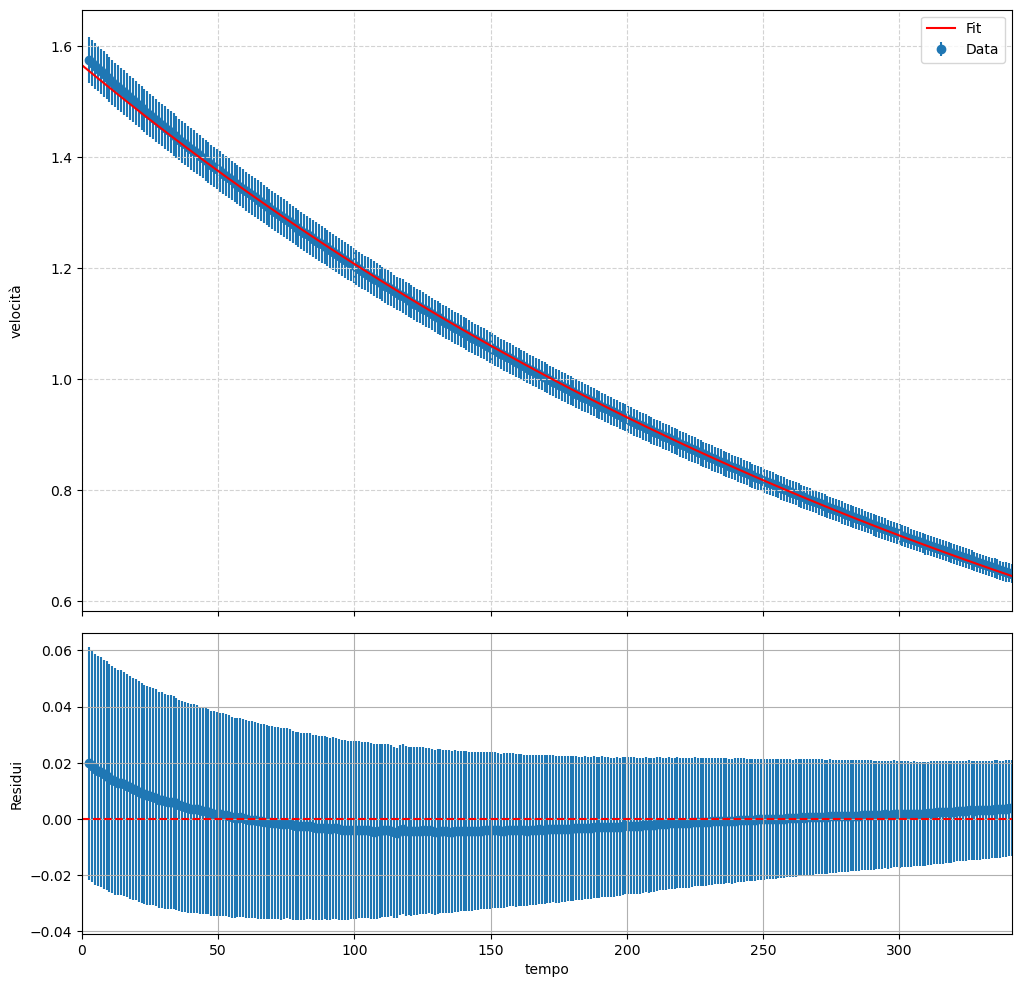

In [15]:
# Create the main figure...
fig = plt.figure(figsize=(12, 12))
ax1, ax2 = fig.subplots(2, 1, sharex=True, gridspec_kw=dict(height_ratios=[2, 1], hspace=0.05))

# Main plot: the scatter plot of x vs. y, on the top panel.
ax1.errorbar(df.t, df.v0, yerr=sigma_v0, fmt='o', label='Data', zorder=1)
xgrid = np.linspace(0.0, max(df.t), 100)
ax1.plot(xgrid, exp_decay(xgrid, *popt), label='Fit', c='red', zorder=2)

# Residui con barre di errore
residuals = df.v0 - exp_decay(df.t, *popt)
ax2.errorbar(df.t, residuals, yerr=sigma_v0, fmt='o', zorder=1)
ax2.axhline(0, color='red', linestyle='--', zorder=2)
ax2.set_xlabel("tempo")
ax2.set_ylabel("Residui")
ax2.grid()

plt.tight_layout()


ax1.set_ylabel('velocità')
ax1.grid(color='lightgray', ls='dashed')
ax1.legend()

plt.xlim(0.0, max(df.t))
fig.align_ylabels((ax1, ax2))

plt.show()

Text(0, 0.5, 'Period')

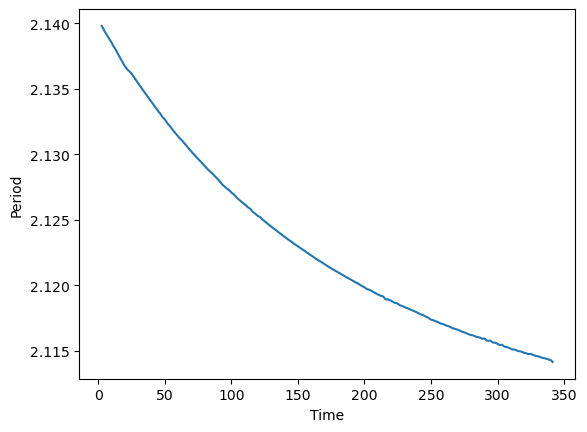

In [24]:
plt.errorbar(df.t, df['T'])
plt.xlabel('Time')
plt.ylabel('Period')

/tmp/ipykernel_13423/2952953279.py:18: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


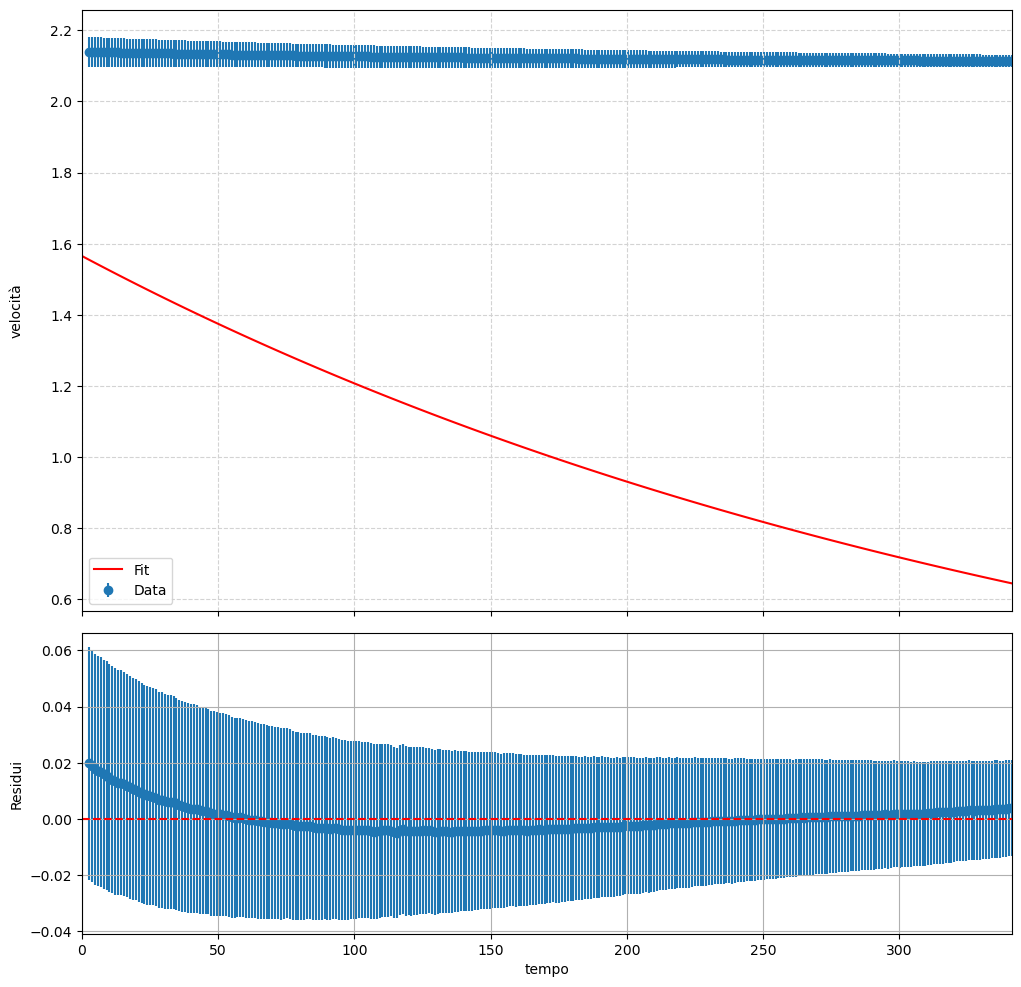

In [23]:
# Create the main figure...
fig = plt.figure(figsize=(12, 12))
ax1, ax2 = fig.subplots(2, 1, sharex=True, gridspec_kw=dict(height_ratios=[2, 1], hspace=0.05))

# Main plot: the scatter plot of x vs. y, on the top panel.
ax1.errorbar(df.t, df['T'], yerr=sigma_v0, fmt='o', label='Data', zorder=1)
xgrid = np.linspace(0.0, max(df.t), 100)
ax1.plot(xgrid, exp_decay(xgrid, *popt), label='Fit', c='red', zorder=2)

# Residui con barre di errore
residuals = df.v0 - exp_decay(df.t, *popt)
ax2.errorbar(df.t, residuals, yerr=sigma_v0, fmt='o', zorder=1)
ax2.axhline(0, color='red', linestyle='--', zorder=2)
ax2.set_xlabel("tempo")
ax2.set_ylabel("Residui")
ax2.grid()

plt.tight_layout()


ax1.set_ylabel('velocità')
ax1.grid(color='lightgray', ls='dashed')
ax1.legend()

plt.xlim(0.0, max(df.t))
fig.align_ylabels((ax1, ax2))

plt.show()

#### Chi square

In [10]:
chi2 = np.sum((residuals / sigma_v0)**2)

dof = len(df.v0) - len(popt)
chi2_red = chi2 / dof

TO compute chi square

residuals = [df.v0 - exp_decay(timestamp_val, *popt) for timestamp_val in df.t]

this formula for residuals is WRONG!!! it gives me a chi sqaure way too high  

residuals = df.v0 - exp_decay(df.t, *popt)   
this is right


In [11]:
chi2_red

0.019411509396937317

### Measure theta

In [12]:
df.theta0= np.arccos(1 - df.v0**2 / (2 * g * l))

/tmp/ipykernel_13423/2127272366.py:1: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df.theta0= np.arccos(1 - df.v0**2 / (2 * g * l))


!!! df.T is a command to transpose, can't use  
must use  
df["T"]  

In [13]:
T0 = 2 * np.pi * np.sqrt(l/g) + (df.theta0 * 0)
T2 = T0 * (1+df.theta0**2/16)
T4 = T0 * (1+df.theta0**2/16 + df.theta0**4/3072)

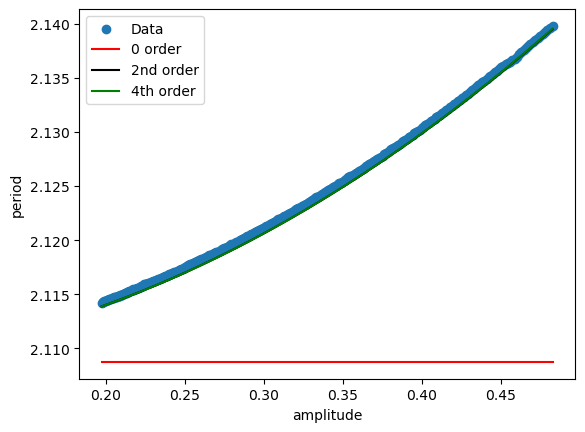

In [14]:
plt.figure()

plt.scatter(df.theta0, df['T'], label="Data")
plt.plot(df.theta0, T0, 'red', label='0 order')
plt.plot(df.theta0, T2, 'black', zorder=1, label='2nd order')
plt.plot(df.theta0, T4, 'green', zorder=2, label='4th order')


plt.xlabel("amplitude")
plt.ylabel("period")
plt.legend()
plt.show()
